# Set up

In [11]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebook" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score, f1_score
 
from src.config import RAW_DATA_PATH, RANDOM_STATE, TEST_SIZE, COLS_TO_SCALE, OUTPUT_DIR, FIGURE_DIR
from src.preprocess import load_and_clean_data, split_train_test
from src.model_logistic import run_model_logistic
from src.model_svm import run_model_svm
from src.model_ANN import run_model_ANN
from src.model_ensemble import run_model_ensemble

# Run model

In [5]:
runs = {
    "Logistic Regression": run_model_logistic,
    "SVM": run_model_svm,
    "ANN": run_model_ANN,
    "XGBoost": run_model_ensemble,
}
models, results = {}, {}
for name, fn in runs.items():
    models[name], results[name] = fn()

Fold 1 -> {'AUPRC': 0.75, 'Recall': 0.893, 'Precision': 0.055, 'F1': 0.104, 'TP': 67, 'FP': 1145, 'FN': 8, 'TN': 44176}
Fold 2 -> {'AUPRC': 0.737, 'Recall': 0.893, 'Precision': 0.049, 'F1': 0.093, 'TP': 67, 'FP': 1298, 'FN': 8, 'TN': 44023}
Fold 3 -> {'AUPRC': 0.697, 'Recall': 0.855, 'Precision': 0.064, 'F1': 0.119, 'TP': 65, 'FP': 952, 'FN': 11, 'TN': 44368}
Fold 4 -> {'AUPRC': 0.757, 'Recall': 0.961, 'Precision': 0.059, 'F1': 0.11, 'TP': 73, 'FP': 1173, 'FN': 3, 'TN': 44147}
Fold 5 -> {'AUPRC': 0.759, 'Recall': 0.934, 'Precision': 0.06, 'F1': 0.113, 'TP': 71, 'FP': 1115, 'FN': 5, 'TN': 44205}
TEST RESULT (MODEL B): {'AUPRC': 0.68, 'Recall': 0.874, 'Precision': 0.056, 'F1': 0.105, 'TP': 83, 'FP': 1403, 'FN': 12, 'TN': 55248}
Saved evaluation figure to: C:\Users\ASUS\Documents\ML\Assignment\ml-project\outputs\figures\model_logistic_evaluation.png
Fold 1 -> {'AUPRC': 0.721, 'Recall': 0.813, 'Precision': 0.735, 'F1': 0.772, 'TP': 61, 'FP': 22, 'FN': 14, 'TN': 45299}
Fold 2 -> {'AUPRC': 0

In [6]:
df_res = pd.DataFrame(results).T[["AUPRC", "Recall", "Precision", "F1", "TP", "FP", "FN", "TN"]]
os.makedirs(OUTPUT_DIR, exist_ok=True)
df_res.to_csv(OUTPUT_DIR / "model_comparison.csv")
df_res

,AUPRC,Recall,Precision,F1,TP,FP,FN,TN
Logistic Regression,0.680,0.874,0.056,0.105,83.0,1403.0,12.0,55248.0
SVM,0.719,0.768,0.745,0.756,73.0,25.0,22.0,56626.0
ANN,0.825,0.747,0.887,0.811,71.0,9.0,24.0,56642.0
XGBoost,0.764,0.726,0.958,0.826,69.0,3.0,26.0,56648.0


# Confusion matrix của 4 model

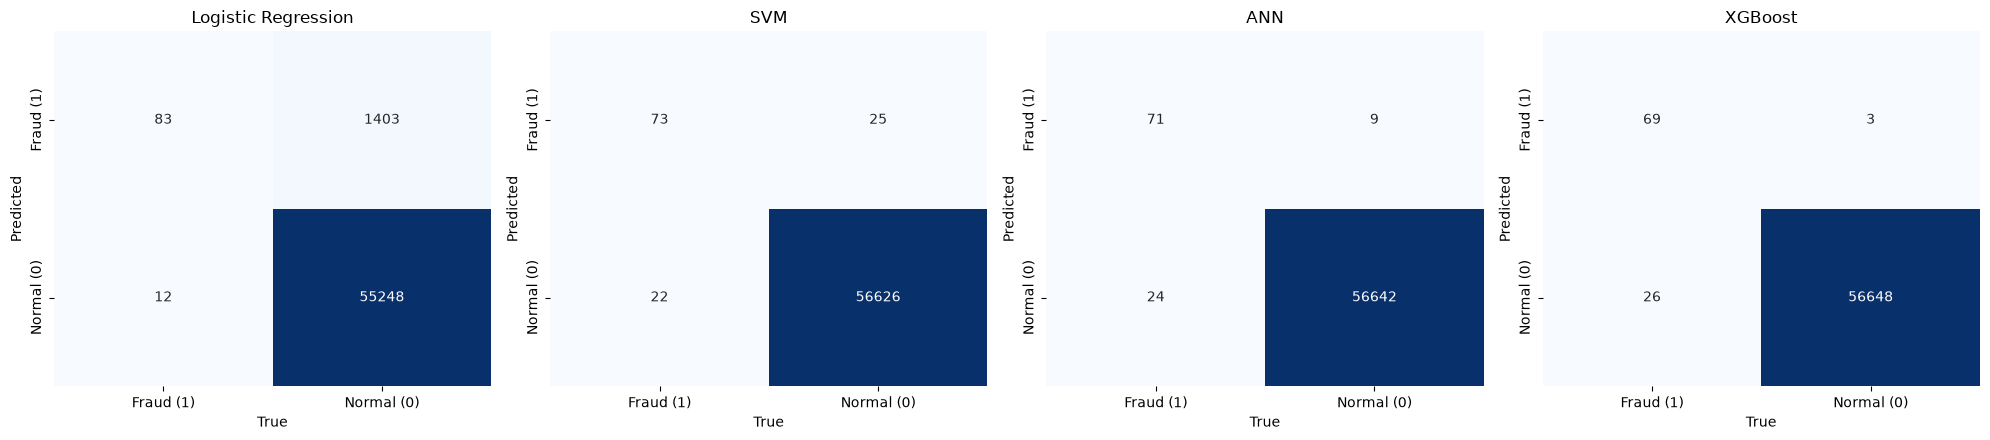

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4.5))
for ax, (name, m) in zip(axes, models.items()):
    pred = (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[1, 0])
    sns.heatmap(cm.T, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Fraud (1)", "Normal (0)"],
                yticklabels=["Fraud (1)", "Normal (0)"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("True"); ax.set_ylabel("Predicted")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "compare_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

# Tổng số lỗi của từng model

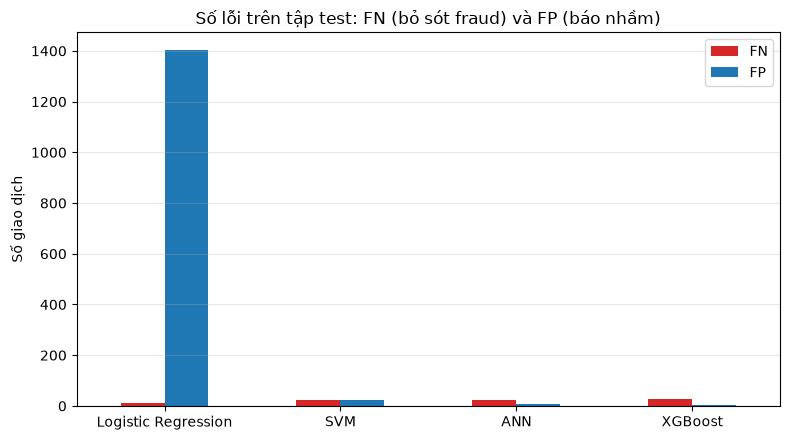

In [16]:
df_res[["FN", "FP"]].plot(kind="bar", figsize=(8, 4.5), color=["#d62728", "#1f77b4"])
plt.title("Số lỗi trên tập test: FN (bỏ sót fraud) và FP (báo nhầm)")
plt.ylabel("Số giao dịch"); plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "compare_errors.png", dpi=200, bbox_inches="tight")
plt.show()

# Biểu đồ cột so sánh 4 metric

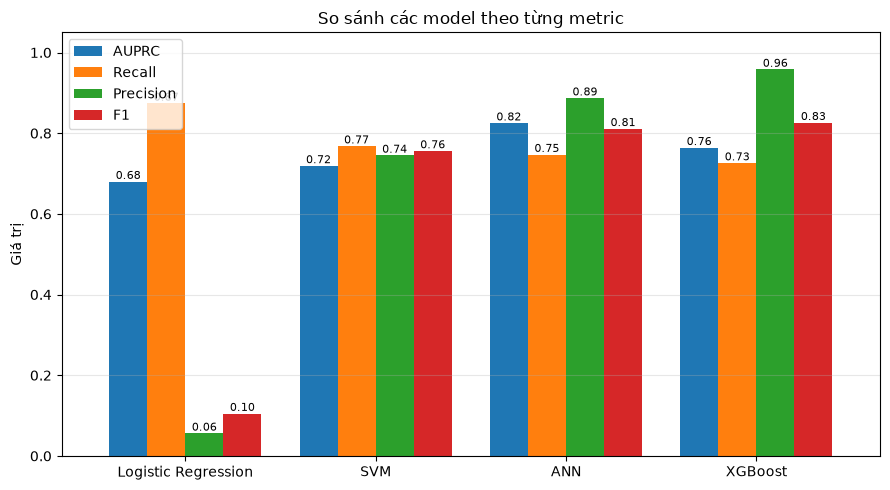

In [17]:
metrics_plot = ["AUPRC", "Recall", "Precision", "F1"]
ax = df_res[metrics_plot].plot(kind="bar", figsize=(9, 5), width=0.8)
ax.set_title("So sánh các model theo từng metric")
ax.set_ylabel("Giá trị")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "compare_metrics_bar.png", dpi=200, bbox_inches="tight")
plt.show()

# So sánh Precision-Recall Curve

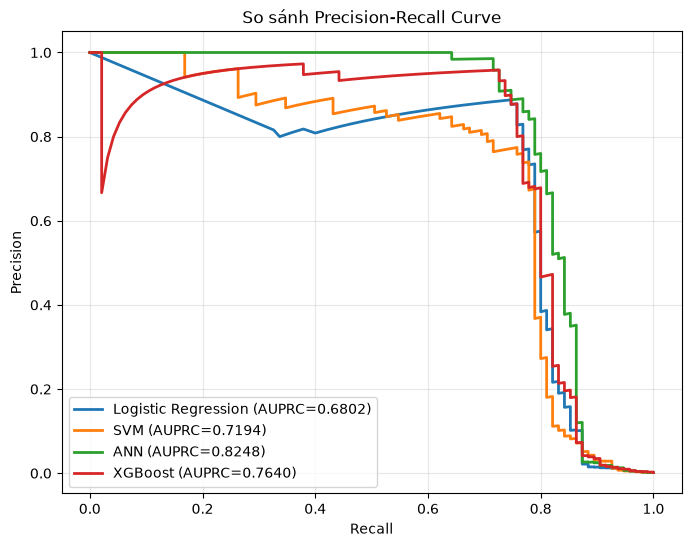

In [18]:
df = load_and_clean_data(RAW_DATA_PATH)
X_train, X_test, y_train, y_test = split_train_test(df, TEST_SIZE, RANDOM_STATE)
sc = RobustScaler()
X_train[COLS_TO_SCALE] = sc.fit_transform(X_train[COLS_TO_SCALE])
X_test[COLS_TO_SCALE] = sc.transform(X_test[COLS_TO_SCALE])

plt.figure(figsize=(8, 6))
for name, m in models.items():
    prob = m.predict_proba(X_test)[:, 1]
    p, r, _ = precision_recall_curve(y_test, prob)
    plt.plot(r, p, lw=2, label=f"{name} (AUPRC={average_precision_score(y_test, prob):.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("So sánh Precision-Recall Curve"); plt.grid(alpha=0.3); plt.legend()
plt.savefig(FIGURE_DIR / "compare_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# Precision, Recall, F1 theo threshold

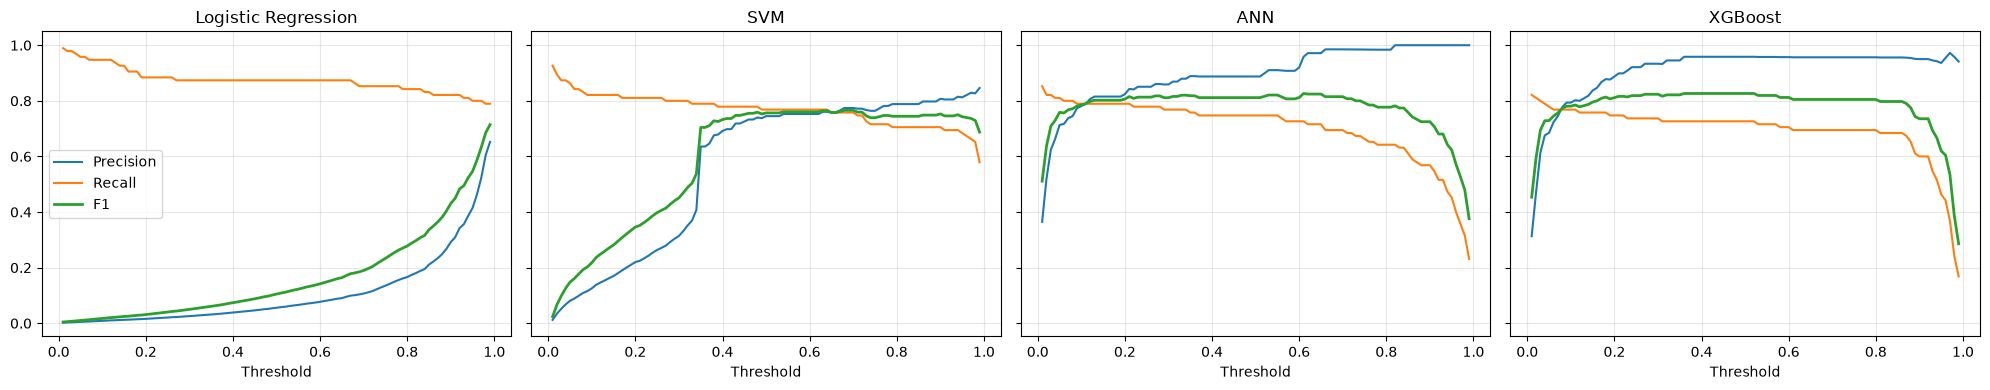

In [19]:
import numpy as np

ths = np.linspace(0.01, 0.99, 99)
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    prob = m.predict_proba(X_test)[:, 1]
    P, R, F = [], [], []
    for t in ths:
        pred = (prob >= t).astype(int)
        P.append(precision_score(y_test, pred, zero_division=0))
        R.append(recall_score(y_test, pred, zero_division=0))
        F.append(f1_score(y_test, pred, zero_division=0))
    ax.plot(ths, P, label="Precision")
    ax.plot(ths, R, label="Recall")
    ax.plot(ths, F, label="F1", lw=2)
    ax.set_title(name); ax.set_xlabel("Threshold"); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "compare_threshold_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

Hình này cho thấy rõ sự đánh đổi Precision và Recall khi đổi threshold